# Introduction to Machine Learning – Lab 1
## Exploratory Data Analysis of the Ames Housing Dataset

The **Ames Housing dataset** was compiled by Dean De Cock as a modern benchmark dataset for machine-learning experiments and serves as a more detailed alternative to the classic Boston Housing dataset. It documents residential property sales in Ames, Iowa, between 2006 and 2010 and contains 2,930 observations of 82 variables: two identifiers (`Order`, `PID`), 79 features and the sale price.

### 1. Loading the dataset
- **File format:** The source file is tab-separated (`sep="\t"`), so the delimiter has to be set explicitly in pandas.
- **Missing values:** In this dataset the string `NA` mostly means "feature not present" (e.g. *no pool*, *no garage*), not "value unknown". Therefore only empty cells are read as missing (`keep_default_na=False, na_values=[""]`), and `NA` stays a regular category.
- **Goal:** Read the raw data into a `pandas.DataFrame` and check the dimensions `(2930, 82)`.

In [11]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.ticker import NullFormatter, PercentFormatter

# Common plot style for all figures
sns.set_theme(style="whitegrid")


# Tick labels for price axes in thousands of dollars, e.g. $150k
def k_dollars(x, _):
    return f"${x / 1000:,.0f}k"


# Path to dataset
DATA_PATH = Path("../data/AmesHousing.csv")

# Load tab-separated file; only empty cells are missing, the string "NA" stays a category
housing = pd.read_csv(DATA_PATH, sep="\t", keep_default_na=False, na_values=[""])

# Verify parsed dimensions
print(f"Dataset shape: {housing.shape}")
housing.head()

Dataset shape: (2930, 82)


,Order,PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,...,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
0,1,526301100,20,RL,141.0,31770,Pave,NA,IR1,Lvl,...,0,NA,NA,NA,0,5,2010,WD,Normal,215000
1,2,526350040,20,RH,80.0,11622,Pave,NA,Reg,Lvl,...,0,NA,MnPrv,NA,0,6,2010,WD,Normal,105000
2,3,526351010,20,RL,81.0,14267,Pave,NA,IR1,Lvl,...,0,NA,NA,Gar2,12500,6,2010,WD,Normal,172000
3,4,526353030,20,RL,93.0,11160,Pave,NA,Reg,Lvl,...,0,NA,NA,NA,0,4,2010,WD,Normal,244000
4,5,527105010,60,RL,74.0,13830,Pave,NA,IR1,Lvl,...,0,NA,MnPrv,NA,0,3,2010,WD,Normal,189900


### 2. Initial data inspection and missing values

Before creating any visualizations, the structure of the data is checked systematically:

1. **Data types and memory layout (`housing.info()`):**
   - Distinguish numerical features (e.g. areas, construction years) from categorical features (e.g. neighborhood, building type).
2. **Summary statistics (`housing.describe()`):**
   - Overview of central tendency (mean, median) and spread (standard deviation, min/max, quartiles) to spot extreme values early.
3. **Missing values (`housing.isna()`):**
   - Find the attributes with a high share of `NaN` values. Because `NA` is kept as a category when loading, `isna()` only counts empty cells here.
   - **Important domain note:** According to the data documentation, the value `NA` in many amenity features (such as `Pool QC`, `Misc Feature`, `Alley`, `Fence`, `Fireplace Qu`, `Garage Type`, `Bsmt Qual`) does not mean that data is missing, but that the property does not have the feature (e.g. *no pool* or *no garage*). Plot 1 separates these two kinds of gaps.

In [13]:
# 1. Summary of data types and non-null counts
print("--- Dataset Info ---")
housing.info()

# 2. Summary statistics for numerical features
print("\n--- Summary Statistics (Numerical) ---")
display(housing.drop(columns=["Order", "PID"]).describe().T.round(2))

# 3. Check columns with highest missing value counts
print("\n--- Top 15 Columns by Missing Values ---")
missing_counts = housing.isna().sum()
missing_percent = (housing.isna().sum() / len(housing)) * 100
missing_df = pd.DataFrame({"Missing Count": missing_counts, "Percentage (%)": missing_percent})
display(missing_df[missing_df["Missing Count"] > 0].sort_values(by="Missing Count", ascending=False).head(15))

--- Dataset Info ---
<class 'pandas.DataFrame'>
RangeIndex: 2930 entries, 0 to 2929
Data columns (total 82 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Order            2930 non-null   int64  
 1   PID              2930 non-null   int64  
 2   MS SubClass      2930 non-null   int64  
 3   MS Zoning        2930 non-null   str    
 4   Lot Frontage     2440 non-null   float64
 5   Lot Area         2930 non-null   int64  
 6   Street           2930 non-null   str    
 7   Alley            2930 non-null   str    
 8   Lot Shape        2930 non-null   str    
 9   Land Contour     2930 non-null   str    
 10  Utilities        2930 non-null   str    
 11  Lot Config       2930 non-null   str    
 12  Land Slope       2930 non-null   str    
 13  Neighborhood     2930 non-null   str    
 14  Condition 1      2930 non-null   str    
 15  Condition 2      2930 non-null   str    
 16  Bldg Type        2930 non-null   str    
 17  Hous

,count,mean,std,min,25%,50%,75%,max
MS SubClass,2930.0,57.39,42.64,20.0,20.00,50.0,70.00,190.0
Lot Frontage,2440.0,69.22,23.37,21.0,58.00,68.0,80.00,313.0
Lot Area,2930.0,10147.92,7880.02,1300.0,7440.25,9436.5,11555.25,215245.0
Overall Qual,2930.0,6.09,1.41,1.0,5.00,6.0,7.00,10.0
Overall Cond,2930.0,5.56,1.11,1.0,5.00,5.0,6.00,9.0
Year Built,2930.0,1971.36,30.25,1872.0,1954.00,1973.0,2001.00,2010.0
Year Remod/Add,2930.0,1984.27,20.86,1950.0,1965.00,1993.0,2004.00,2010.0
Mas Vnr Area,2907.0,101.90,179.11,0.0,0.00,0.0,164.00,1600.0
BsmtFin SF 1,2929.0,442.63,455.59,0.0,0.00,370.0,734.00,5644.0
BsmtFin SF 2,2929.0,49.72,169.17,0.0,0.00,0.0,0.00,1526.0



--- Top 15 Columns by Missing Values ---


,Missing Count,Percentage (%)
Lot Frontage,490,16.723549
Garage Yr Blt,159,5.426621
Mas Vnr Type,23,0.784983
Mas Vnr Area,23,0.784983
Bsmt Exposure,4,0.136519
Garage Finish,2,0.068259
Bsmt Half Bath,2,0.068259
Bsmt Full Bath,2,0.068259
BsmtFin Type 2,2,0.068259
Bsmt Cond,1,0.034130


### Plot 1: Structural vs. truly missing values

**Question:** Which columns have missing values – and is the value unknown, or does the feature simply not exist?

**Motivation:** With pandas' default loading, 27 columns contain `NaN`, some of them almost completely empty, which tempts you to drop them. The data documentation, however, defines `NA` as "No Pool", "No Garage" and so on. The useful question is therefore which gaps are real.

**Plot:** Stacked horizontal bars per column: the share of houses where the feature does not exist (grey, category `NA`) and the share of truly missing values (red, empty cells). `Garage Yr Blt` is numeric, so houses without a garage have an empty cell instead of `NA`; these cells are counted as "feature not present".

Columns with gaps: 27


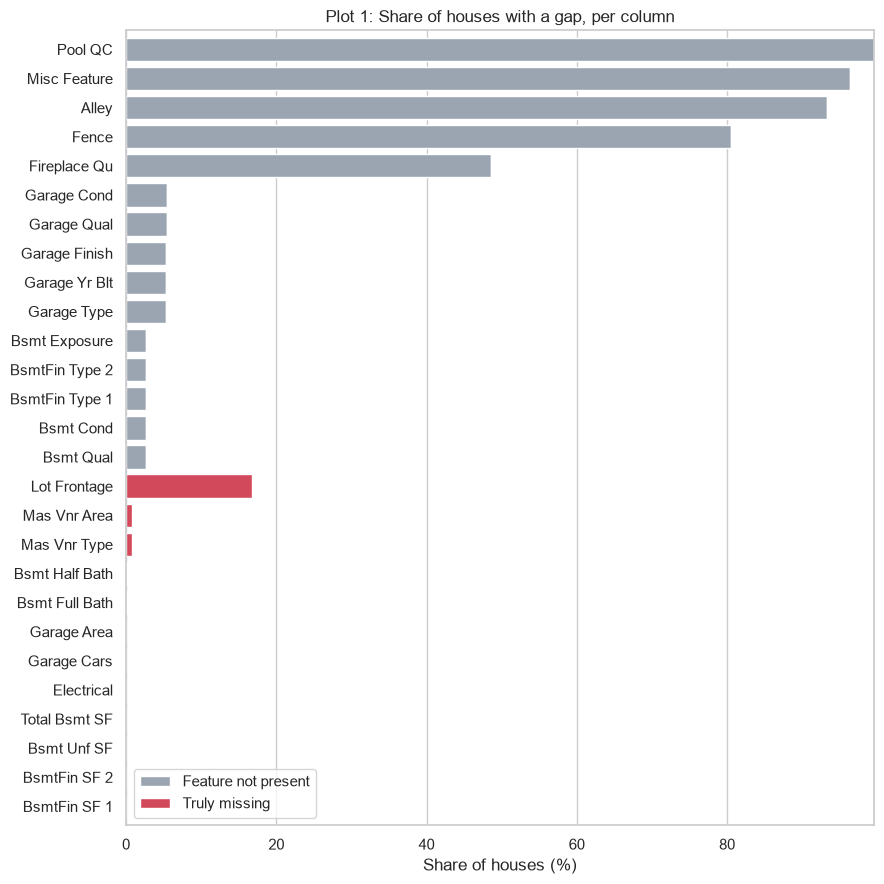

,Feature not present,Truly missing
Pool QC,99.56,0.00
Misc Feature,96.38,0.00
Alley,93.24,0.00
Fence,80.48,0.00
Fireplace Qu,48.53,0.00
Garage Cond,5.39,0.03
Garage Qual,5.39,0.03
Garage Finish,5.36,0.07
Garage Yr Blt,5.36,0.07
Garage Type,5.36,0.00


In [9]:
# "NA" = feature not present (structural), empty cell = value truly missing
structural = (housing == "NA").sum()
no_garage = housing["Garage Type"] == "NA"
structural["Garage Yr Blt"] = no_garage.sum()  # numeric column: empty instead of "NA"
genuine = housing.isna().sum()
genuine["Garage Yr Blt"] -= no_garage.sum()

miss = (
    pd.DataFrame({"Feature not present": structural, "Truly missing": genuine})
    .loc[lambda d: d.sum(axis=1) > 0]
    .div(len(housing))
    .mul(100)
    .sort_values(["Feature not present", "Truly missing"])
)
print(f"Columns with gaps: {len(miss)}")

ax = miss.plot.barh(stacked=True, figsize=(9, 9), color=["#9aa5b1", "#d1495b"], width=0.8)
ax.grid(axis="y", visible=False)
ax.set_title("Plot 1: Share of houses with a gap, per column")
ax.set_xlabel("Share of houses (%)")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

display(miss.iloc[::-1].round(2))

**Findings:**
- 27 columns contain gaps. Feature not present: `Pool QC` 99.6 %, `Misc Feature` 96.4 %, `Alley` 93.2 %, `Fence` 80.5 %, `Fireplace Qu` 48.5 %, all garage columns 5.4 %, all basement columns 2.7 %.
- Truly missing: `Lot Frontage` 16.7 %, `Mas Vnr Type` / `Mas Vnr Area` 0.8 %, every other column ≤ 0.14 % (at most 4 houses).

**How to read it:** A long grey bar is information (the house does not have the feature), not data loss. Columns of one group share the same bar length (all garage columns 5.4 %) because the same houses are affected. Only the red bars are an imputation problem.

**Consequence:** No column is dropped because of missing values. Absent features stay a category of their own (or 0 for areas) and can become flags such as `has_garage`. Only `Lot Frontage` needs a real imputation (e.g. the median per neighborhood). It is left to the modelling pipeline, so that it can be fitted on the training data only.

### 3. Data preparation for the plots

Plots 2–10 use a lightly cleaned copy `housing_clean` (still all 2,930 houses) and a numerically encoded copy `encoded`:

- **Feature types:** The data documentation classifies the 79 features as 23 nominal, 23 ordinal, 14 discrete and 19 continuous; `SalePrice` is the target.
- **Structural gaps:** `NA` stays a category of its own. Empty basement areas and bathroom counts of houses without a basement are set to 0. `Garage Yr Blt` stays empty for houses without a garage, because no year makes sense there.
- **Small real gaps:** The 23 houses without masonry veneer information are treated as "no veneer" (`None` / 0), by far the most frequent case. The remaining single gaps (at most 4 houses per column) stay `NaN`; pandas skips them in counts, plots and correlations. `Lot Frontage` is not imputed here (see Plot 1).
- **Typo:** One garage is recorded as built in 2207; this is corrected to 2007.
- **Extreme houses:** The five houses with more than 4,000 ft² of living area are kept, but flagged as `is_extreme` (see Plot 6).
- **Encoding:** For correlations, the ordinal grades are mapped to integers in their natural order (e.g. `NA` < `Po` < `Fa` < `TA` < `Gd` < `Ex` → 0–5), and `Central Air` to 0/1.

In [10]:
target = "SalePrice"

# Feature types according to the data documentation (column names as in the CSV file)
nominal = [
    "MS SubClass", "MS Zoning", "Street", "Alley", "Land Contour", "Lot Config", "Neighborhood",
    "Condition 1", "Condition 2", "Bldg Type", "House Style", "Roof Style", "Roof Matl",
    "Exterior 1st", "Exterior 2nd", "Mas Vnr Type", "Foundation", "Heating", "Central Air",
    "Garage Type", "Misc Feature", "Sale Type", "Sale Condition",
]
ordinal = [
    "Lot Shape", "Utilities", "Land Slope", "Overall Qual", "Overall Cond", "Exter Qual",
    "Exter Cond", "Bsmt Qual", "Bsmt Cond", "Bsmt Exposure", "BsmtFin Type 1", "BsmtFin Type 2",
    "Heating QC", "Electrical", "Kitchen Qual", "Functional", "Fireplace Qu", "Garage Finish",
    "Garage Qual", "Garage Cond", "Paved Drive", "Pool QC", "Fence",
]
discrete = [
    "Year Built", "Year Remod/Add", "Bsmt Full Bath", "Bsmt Half Bath", "Full Bath", "Half Bath",
    "Bedroom AbvGr", "Kitchen AbvGr", "TotRms AbvGrd", "Fireplaces", "Garage Yr Blt",
    "Garage Cars", "Mo Sold", "Yr Sold",
]
continuous = [
    "Lot Frontage", "Lot Area", "Mas Vnr Area", "BsmtFin SF 1", "BsmtFin SF 2", "Bsmt Unf SF",
    "Total Bsmt SF", "1st Flr SF", "2nd Flr SF", "Low Qual Fin SF", "Gr Liv Area", "Garage Area",
    "Wood Deck SF", "Open Porch SF", "Enclosed Porch", "3Ssn Porch", "Screen Porch", "Pool Area",
    "Misc Val",
]
print(f"Nominal: {len(nominal)}, ordinal: {len(ordinal)}, discrete: {len(discrete)}, continuous: {len(continuous)}")

housing_clean = housing.copy()

# No basement -> empty basement areas and bathroom counts become 0
no_basement = housing_clean["Bsmt Qual"] == "NA"
bsmt_numeric = ["BsmtFin SF 1", "BsmtFin SF 2", "Bsmt Unf SF", "Total Bsmt SF", "Bsmt Full Bath", "Bsmt Half Bath"]
housing_clean.loc[no_basement, bsmt_numeric] = housing_clean.loc[no_basement, bsmt_numeric].fillna(0)

# Unknown masonry veneer -> no veneer, by far the most frequent case
housing_clean["Mas Vnr Type"] = housing_clean["Mas Vnr Type"].fillna("None")
housing_clean["Mas Vnr Area"] = housing_clean["Mas Vnr Area"].fillna(0)

# Typo in the raw data: a garage built in 2207
housing_clean["Garage Yr Blt"] = housing_clean["Garage Yr Blt"].replace(2207, 2007)

# Houses above 4,000 ft² are kept, but flagged (see Plot 6)
housing_clean["is_extreme"] = housing_clean["Gr Liv Area"] > 4000
print(f"Houses flagged as extreme: {housing_clean['is_extreme'].sum()}")

# Ordinal grades -> integers in their natural order (0 = feature not present)
quality = {"NA": 0, "Po": 1, "Fa": 2, "TA": 3, "Gd": 4, "Ex": 5}
finish_type = {"NA": 0, "Unf": 1, "LwQ": 2, "Rec": 3, "BLQ": 4, "ALQ": 5, "GLQ": 6}
ordinal_maps = {
    "Lot Shape": {"IR3": 0, "IR2": 1, "IR1": 2, "Reg": 3},
    "Utilities": {"ELO": 0, "NoSeWa": 1, "NoSewr": 2, "AllPub": 3},
    "Land Slope": {"Sev": 0, "Mod": 1, "Gtl": 2},
    "Exter Qual": quality,
    "Exter Cond": quality,
    "Bsmt Qual": quality,
    "Bsmt Cond": quality,
    "Bsmt Exposure": {"NA": 0, "No": 1, "Mn": 2, "Av": 3, "Gd": 4},
    "BsmtFin Type 1": finish_type,
    "BsmtFin Type 2": finish_type,
    "Heating QC": quality,
    "Electrical": {"Mix": 0, "FuseP": 1, "FuseF": 2, "FuseA": 3, "SBrkr": 4},
    "Kitchen Qual": quality,
    "Functional": {"Sal": 0, "Sev": 1, "Maj2": 2, "Maj1": 3, "Mod": 4, "Min2": 5, "Min1": 6, "Typ": 7},
    "Fireplace Qu": quality,
    "Garage Finish": {"NA": 0, "Unf": 1, "RFn": 2, "Fin": 3},
    "Garage Qual": quality,
    "Garage Cond": quality,
    "Paved Drive": {"N": 0, "P": 1, "Y": 2},
    "Pool QC": quality,
    "Fence": {"NA": 0, "MnWw": 1, "GdWo": 2, "MnPrv": 3, "GdPrv": 4},
}

encoded = housing_clean.copy()
for col, mapping in ordinal_maps.items():
    encoded[col] = encoded[col].map(mapping)
encoded["Central Air"] = (encoded["Central Air"] == "Y").astype(int)

Nominal: 23, ordinal: 23, discrete: 14, continuous: 19
Houses flagged as extreme: 5


### Plot 2: Distribution of the sale price

**Question:** Are prices symmetric around a typical value, or dominated by a long tail of expensive houses?

**Motivation:** `SalePrice` is the target of Task 2 (regression). Prices are bounded by zero but open upward, and `describe()` shows mean > median. Both suggest right skew, which pulls a squared-error regression toward the expensive tail.

**Plot:** Histograms with a kernel density estimate (KDE) of the raw price (left) and of `log(SalePrice)` (right), each with mean and median marked. Skewness, kurtosis and the number of houses flagged by the 1.5 × IQR outlier rule are printed for both scales.

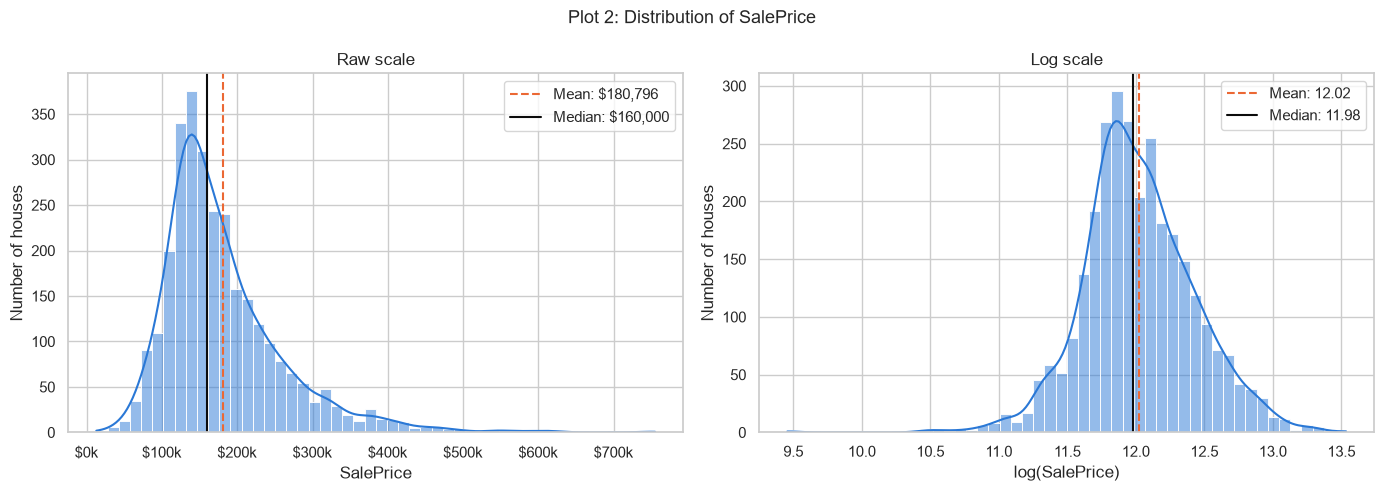

Raw: skewness 1.74, kurtosis 5.12, IQR-rule outliers: 0 low, 137 high
Log: skewness -0.01, kurtosis 1.51, IQR-rule outliers: 28 low, 32 high


In [5]:
price = housing_clean[target]
log_price = np.log(price)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(price, bins=50, kde=True, color="#2a78d6", ax=axes[0])
axes[0].axvline(price.mean(), color="#eb6834", linestyle="--", linewidth=1.5, label=f"Mean: ${price.mean():,.0f}")
axes[0].axvline(price.median(), color="#0b0b0b", linewidth=1.5, label=f"Median: ${price.median():,.0f}")
axes[0].xaxis.set_major_formatter(k_dollars)
axes[0].set_title("Raw scale")
axes[0].set_xlabel("SalePrice")

sns.histplot(log_price, bins=50, kde=True, color="#2a78d6", ax=axes[1])
axes[1].axvline(log_price.mean(), color="#eb6834", linestyle="--", linewidth=1.5, label=f"Mean: {log_price.mean():.2f}")
axes[1].axvline(log_price.median(), color="#0b0b0b", linewidth=1.5, label=f"Median: {log_price.median():.2f}")
axes[1].set_title("Log scale")
axes[1].set_xlabel("log(SalePrice)")

for ax in axes:
    ax.set_ylabel("Number of houses")
    ax.legend()
fig.suptitle("Plot 2: Distribution of SalePrice", fontsize=13)
plt.tight_layout()
plt.show()

for name, values in [("Raw", price), ("Log", log_price)]:
    q1, q3 = values.quantile([0.25, 0.75])
    low, high = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
    print(
        f"{name}: skewness {values.skew():.2f}, kurtosis {values.kurt():.2f}, "
        f"IQR-rule outliers: {(values < low).sum()} low, {(values > high).sum()} high"
    )

**Findings:** Raw price: median \$160,000, mean \$180,796, skewness 1.74, kurtosis 5.12. Log price: skewness −0.01, kurtosis 1.51. The 1.5 × IQR rule flags 137 houses on the raw scale, all of them on the expensive side, but only 60 on the log scale (28 low, 32 high).

**How to read it:** A long right tail with mean > median is right skew. After the log transform the shape is nearly symmetric, and differences become relative: a \$20,000 error matters more on a \$100,000 house than on a \$500,000 one.

**Consequence:** Model `log(SalePrice)` in Task 2 and back-transform the predictions with `np.exp`. The skew also explains the 137 "outliers" of the raw IQR rule: they are mostly the natural tail of a skewed distribution, not errors, so they are not removed.

### Plot 3: Distributions of all continuous features

**Question:** Which continuous features are strongly skewed or mostly zero, and therefore need a transform or a presence flag?

**Motivation:** 19 continuous columns are too many to inspect one at a time; small multiples show every shape at once. Area columns use 0 for "not present" (no second floor, no porch), which neither a mean nor a linear model handles well.

**Plot:** One histogram per continuous feature, followed by a table with the skewness and the share of zeros per column, sorted by skewness.

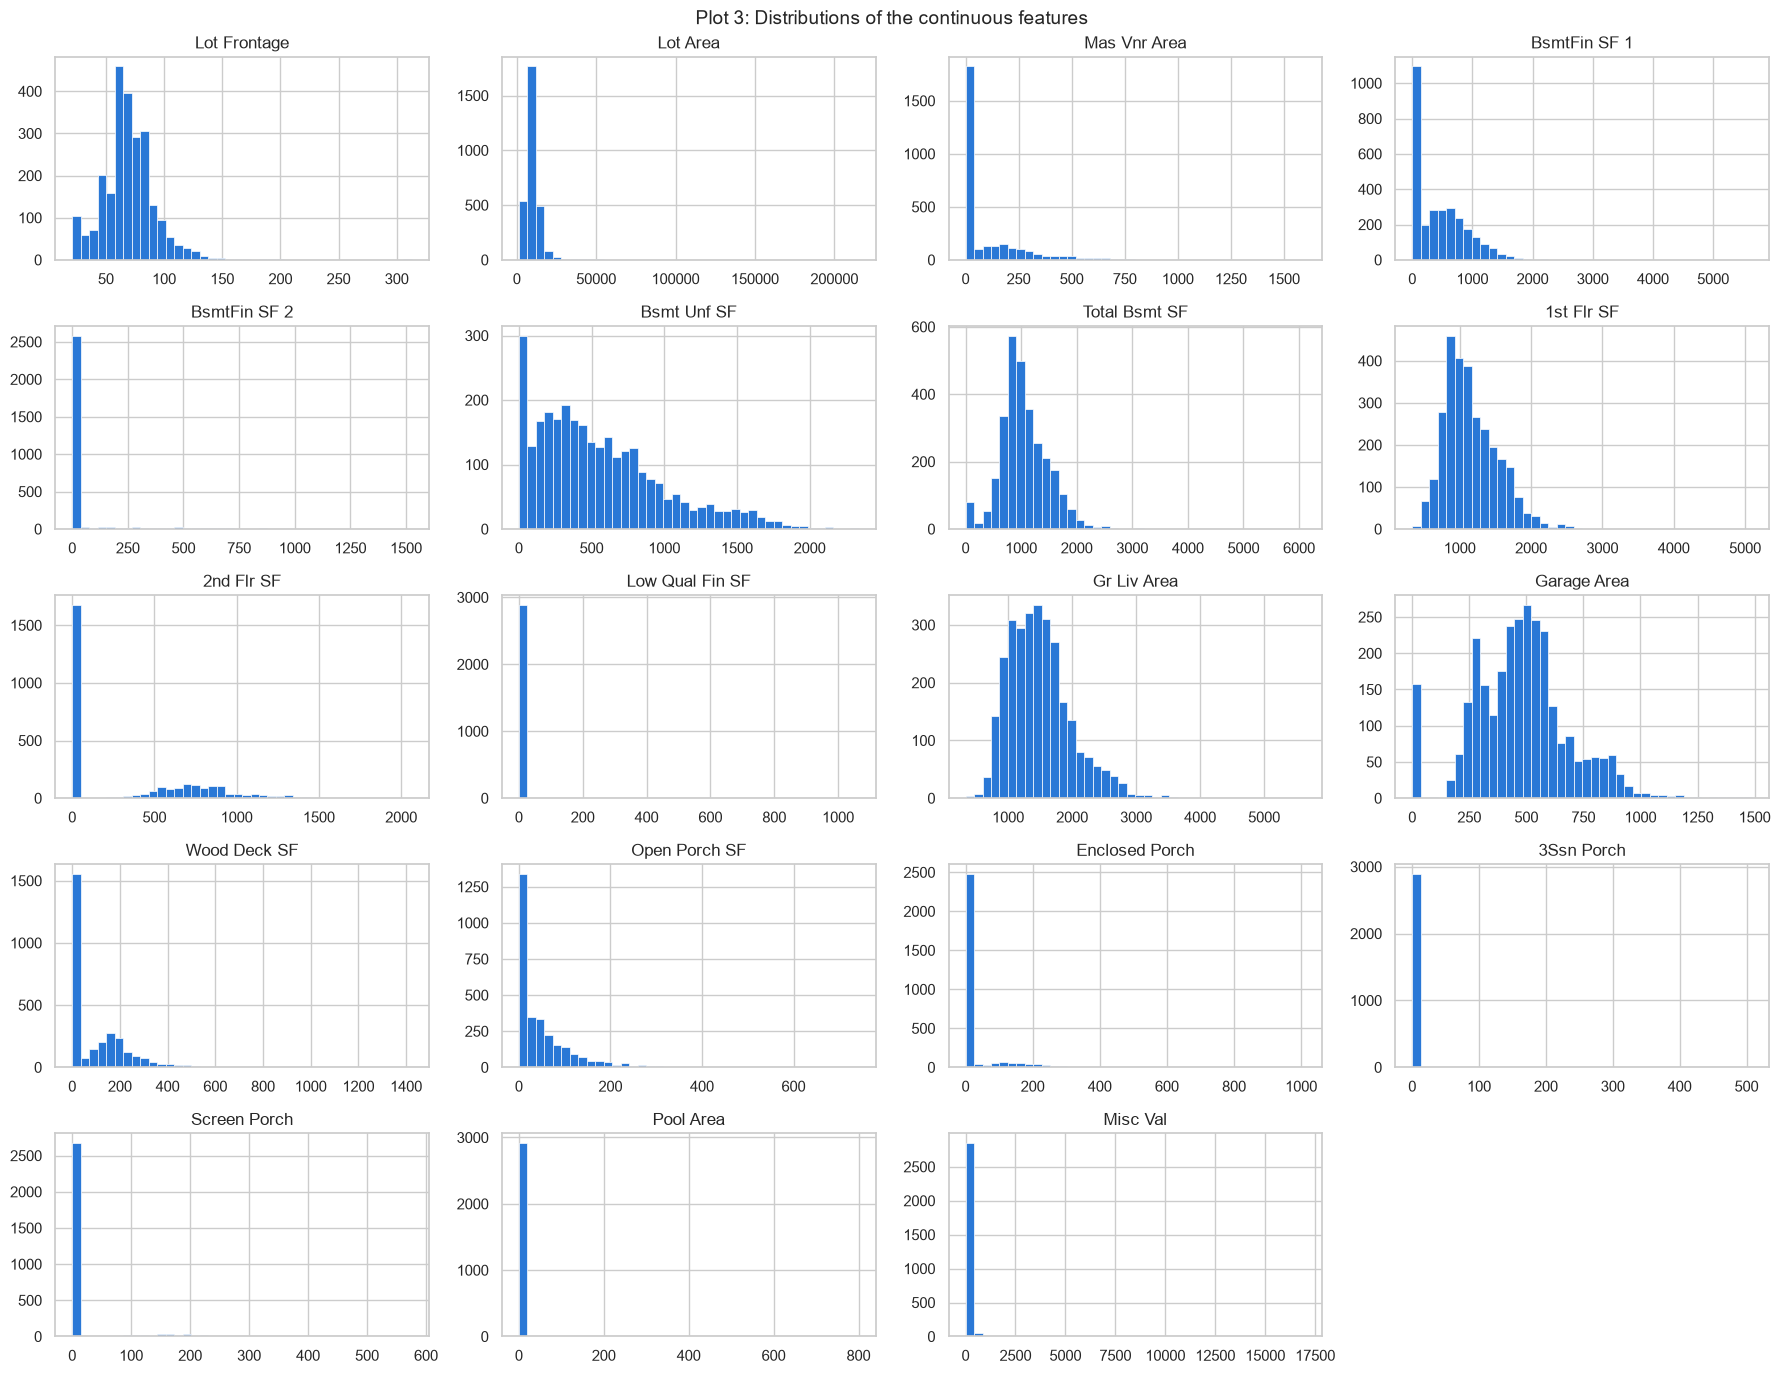

,skewness,zeros (%)
Misc Val,22.00,96.48
Pool Area,16.94,99.56
Lot Area,12.82,0.00
Low Qual Fin SF,12.12,98.63
3Ssn Porch,11.40,98.74
BsmtFin SF 2,4.14,87.99
Enclosed Porch,4.01,84.33
Screen Porch,3.96,91.26
Mas Vnr Area,2.62,60.44
Open Porch SF,2.54,44.37


In [6]:
housing_clean[continuous].hist(
    bins=40, figsize=(18, 14), layout=(5, 4), color="#2a78d6", edgecolor="white", linewidth=0.5
)
plt.suptitle("Plot 3: Distributions of the continuous features", fontsize=14)
plt.tight_layout()
plt.show()

shape = pd.DataFrame({
    "skewness": housing_clean[continuous].skew(),
    "zeros (%)": (housing_clean[continuous] == 0).mean() * 100,
}).sort_values("skewness", ascending=False)
display(shape.round(2))

**Findings:**
- Mostly zero: `Pool Area` 99.6 %, `3Ssn Porch` 98.7 %, `Low Qual Fin SF` 98.6 %, `Misc Val` 96.5 %, `Screen Porch` 91.3 %, `BsmtFin SF 2` 88.0 %, `Enclosed Porch` 84.3 %, `Mas Vnr Area` 60.4 %, `2nd Flr SF` 57.3 %.
- Highest skewness: `Misc Val` 22.0, `Pool Area` 16.9, `Lot Area` 12.8. Nearly symmetric: `Garage Area` (0.24).

**How to read it:** A spike at 0 next to a separate hump means two populations (with and without the feature). A long right tail is a candidate for a log transform. A spike at 0 with almost nothing else is a nearly constant feature.

**Consequence:** Apply `np.log1p` to the skewed areas (`Lot Area`, `Gr Liv Area`, `1st Flr SF`); turn the zero-inflated ones into flags (`has_2nd_floor`, `has_pool`, `has_porch`); the nearly constant ones are candidates for removal. For clustering (Task 3), transform before scaling, otherwise `Lot Area` dominates every distance.

### Plot 4: Nearly constant categorical features

**Question:** Which categorical features carry almost no information because nearly every house has the same value?

**Motivation:** The assignment asks for candidates for removal. A column in which 99 % of the houses share one value cannot separate houses. A rare value might still carry a strong price signal, though, so the prices are checked as well.

**Plot:** The share of the most frequent value for each of the 46 nominal and ordinal features, with a dashed line at 95 % (columns above it in blue). For every column above 95 % and for `Central Air`, the number of houses and the median price per value are printed.

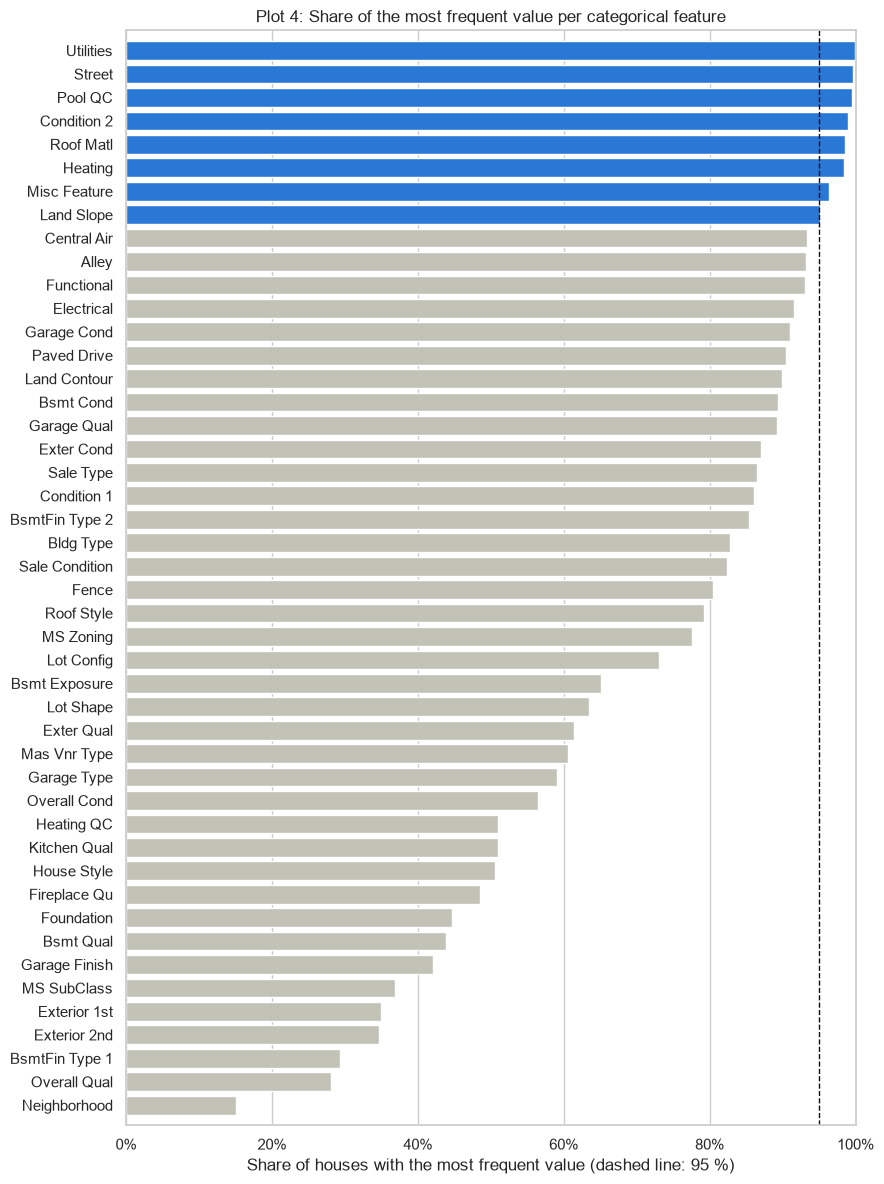


Utilities (most frequent value: 99.9% of houses)
           count    median
Utilities                 
AllPub      2927  160000.0
NoSeWa         1  137500.0
NoSewr         2   86312.5

Street (most frequent value: 99.6% of houses)
        count    median
Street                 
Grvl       12   87425.0
Pave     2918  160375.0

Pool QC (most frequent value: 99.6% of houses)
         count    median
Pool QC                 
Ex           4  465000.0
Fa           2  215500.0
Gd           4  215500.0
NA        2917  160000.0
TA           3  153000.0

Condition 2 (most frequent value: 99.0% of houses)
             count    median
Condition 2                 
Artery           5  118000.0
Feedr           13  128000.0
Norm          2900  160375.0
PosA             4  423500.0
PosN             4  359500.0
RRAe             1  190000.0
RRAn             1  136905.0
RRNn             2   96750.0

Roof Matl (most frequent value: 98.5% of houses)
           count    median
Roof Matl                 
Cly

In [7]:
dom = pd.Series(
    {c: housing_clean[c].value_counts(normalize=True).iloc[0] for c in nominal + ordinal}
).sort_values()

fig, ax = plt.subplots(figsize=(9, 12))
ax.barh(dom.index, dom.values, color=np.where(dom > 0.95, "#2a78d6", "#c3c2b7"))
ax.axvline(0.95, color="#0b0b0b", linestyle="--", linewidth=1)
ax.set_xlim(0, 1)
ax.margins(y=0.01)
ax.grid(axis="y", visible=False)
ax.xaxis.set_major_formatter(PercentFormatter(1.0))
ax.set_title("Plot 4: Share of the most frequent value per categorical feature")
ax.set_xlabel("Share of houses with the most frequent value (dashed line: 95 %)")
plt.tight_layout()
plt.show()

for col in list(dom[dom > 0.95].index[::-1]) + ["Central Air"]:
    print(f"\n{col} (most frequent value: {dom[col]:.1%} of houses)")
    print(housing_clean.groupby(col)[target].agg(["count", "median"]).to_string())

**Findings:** Above 95 %: `Utilities` 99.9 %, `Street` 99.6 %, `Pool QC` 99.6 % (`NA`), `Condition 2` 99.0 %, `Roof Matl` 98.5 %, `Heating` 98.5 %, `Misc Feature` 96.4 %, `Land Slope` 95.2 %. Just below: `Central Air` 93.3 %, `Alley` 93.2 %, `Functional` 93.1 %.

**How to read it:** The longer the bar, the less information the column carries. Rare categories have tiny counts (only 3 houses are not `AllPub`), so their price differences are mostly noise. The counter-example is `Central Air`: only 196 houses lack it, but their median price is \$98,250 vs. \$166,250.

**Consequence:** `Utilities`, `Street`, `Condition 2`, `Roof Matl`, `Heating`, `Pool QC` and `Misc Feature` are candidates for removal. `Land Slope` is just above the threshold, but its 141 houses on moderate or severe slopes are not a tiny group (median prices \$188,000 and \$206,975 vs. \$159,950), so it stays for now. `Central Air` stays despite 93 % dominance.

### Plot 5: Correlation heatmap of the 15 features most related to the price

**Question:** Which features move together with the price, and which features are near-duplicates of each other?

**Motivation:** With 79 features, a first screen is needed before drawing individual plots. The same matrix exposes redundancy, which matters twice later: correlated predictors make linear models unstable (Task 2), and duplicated information counts twice in distance-based clustering (Task 3).

**Plot:** Lower triangle of the Spearman correlation matrix for `SalePrice` and the 15 features with the strongest absolute correlation to it. Spearman instead of Pearson: it works on ranks, so it is robust to the skew and outliers from Plots 2–3, and it is correct for ordinal codes, where only the order carries meaning. The Pearson values are printed next to it for comparison.

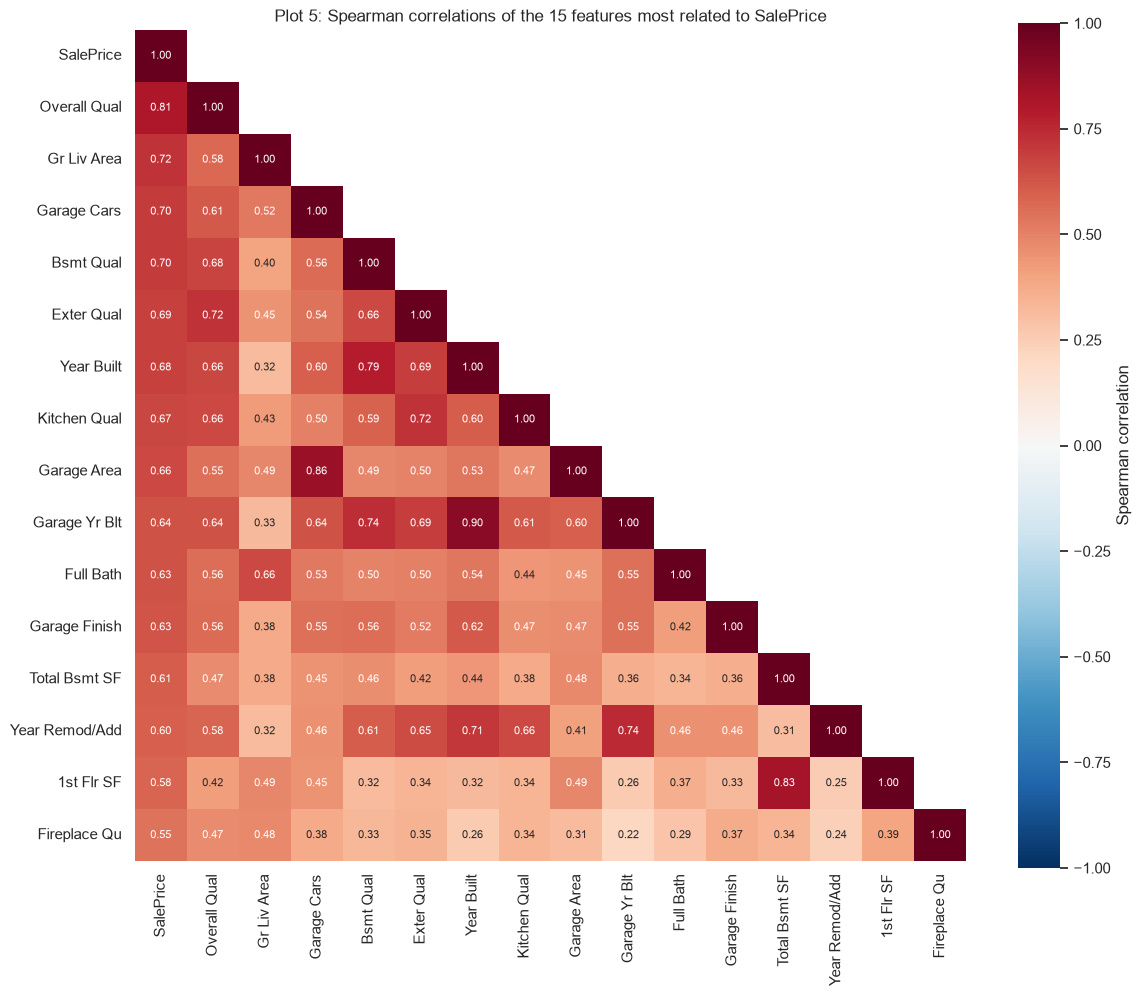

,Spearman,Pearson
SalePrice,1.00,1.00
Overall Qual,0.81,0.80
Gr Liv Area,0.72,0.71
Garage Cars,0.70,0.65
Bsmt Qual,0.70,0.61
Exter Qual,0.69,0.70
Year Built,0.68,0.56
Kitchen Qual,0.67,0.67
Garage Area,0.66,0.64
Garage Yr Blt,0.64,0.53


Smallest correlation in the matrix: 0.22
Overall Cond vs. SalePrice (Spearman): -0.17


In [8]:
num_cols = discrete + continuous + ["Overall Qual", "Overall Cond", "Central Air"] + list(ordinal_maps) + [target]
corr = encoded[num_cols].corr(method="spearman")
top = corr[target].abs().sort_values(ascending=False).index[:16]  # SalePrice + 15 strongest
mask = np.triu(np.ones((len(top), len(top)), dtype=bool), k=1)

plt.figure(figsize=(12, 10))
sns.heatmap(
    corr.loc[top, top],
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    annot_kws={"size": 8},
    cbar_kws={"label": "Spearman correlation"},
)
plt.grid(False)
plt.title("Plot 5: Spearman correlations of the 15 features most related to SalePrice")
plt.tight_layout()
plt.show()

pearson = encoded[num_cols].corr()[target]
display(pd.DataFrame({"Spearman": corr.loc[top, target], "Pearson": pearson[top]}).round(2))
print(f"Smallest correlation in the matrix: {corr.loc[top, top].min().min():.2f}")
print(f"Overall Cond vs. SalePrice (Spearman): {corr.loc['Overall Cond', target]:.2f}")

**Findings:**
- Spearman ρ with the price: `Overall Qual` 0.81, `Gr Liv Area` 0.72, `Garage Cars` 0.70, `Bsmt Qual` 0.70, `Exter Qual` 0.69, `Year Built` 0.68, `Kitchen Qual` 0.67, `Garage Area` 0.66, `Garage Yr Blt` 0.64, `Full Bath` 0.63, `Garage Finish` 0.63, `Total Bsmt SF` 0.61, `Year Remod/Add` 0.60, `1st Flr SF` 0.58, `Fireplace Qu` 0.55.
- Redundant pairs: `Year Built` – `Garage Yr Blt` 0.90, `Garage Cars` – `Garage Area` 0.86, `Total Bsmt SF` – `1st Flr SF` 0.83.
- Every cell of the matrix is positive (minimum 0.22). With Pearson, `Year Built` drops to 0.56, a hint that its relation to the price is not linear.

**How to read it:** The `SalePrice` row ranks the drivers: quality grades, size, garage and age. Off-diagonal cells near 1 mark pairs that carry the same information. That all 15 features also correlate positively with each other means they share one underlying "big, new, well-built house" dimension. Correlation is association, not causation: `Garage Yr Blt` scores 0.64 mainly because it copies `Year Built` (ρ = 0.90).

**Consequence:** Shortlist for Task 2: `Overall Qual`, `Gr Liv Area`, the quality grades, `Garage Cars`, `Total Bsmt SF`, `Year Built`. Keep only one column per redundant pair. For Task 3, expect one dominant size–quality axis; standardize and consider PCA, so that it does not swamp the rest.

### Plot 6: Living area vs. price, colored by sale condition

**Question:** Does the price grow roughly linearly with the living area, and which houses break the pattern – and why?

**Motivation:** `Gr Liv Area` is the strongest size variable in Plot 5 and the most intuitive price driver. A scatter plot shows what a single coefficient hides: curvature, growing spread and individual extreme points. Dean De Cock's original documentation of the dataset points to exactly this plot for spotting unusual sales.

**Plot:** Living area vs. price, colored by `Sale Condition` (the three small groups `Family`, `Alloca` and `AdjLand` are merged into "Other", so that the colors stay distinguishable). Also shown: a straight line fitted to all houses up to 4,000 ft², a dashed line at 4,000 ft², and labels (Order, neighborhood, sale condition) for the five `is_extreme` houses.

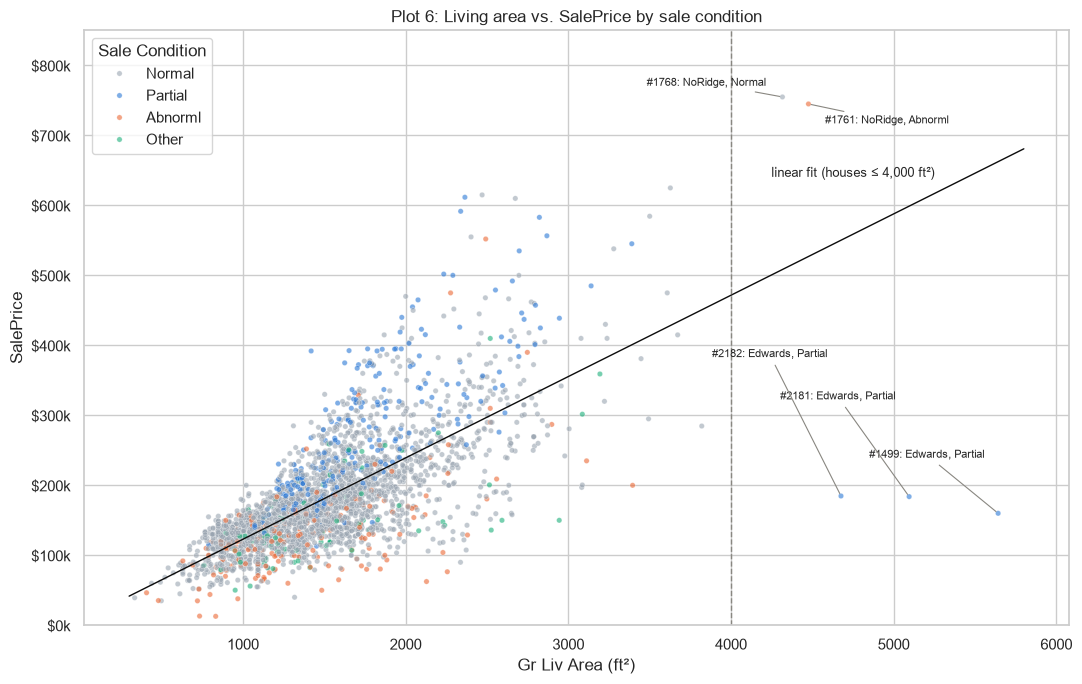

Pearson r (Gr Liv Area, SalePrice): 0.71


,Order,Neighborhood,Sale Condition,Gr Liv Area,SalePrice,Predicted by linear fit
1498,1499,Edwards,Partial,5642,160000,663000
1760,1761,NoRidge,Abnorml,4476,745000,527000
1767,1768,NoRidge,Normal,4316,755000,508000
2180,2181,Edwards,Partial,5095,183850,599000
2181,2182,Edwards,Partial,4676,184750,550000


,Residual std
Gr Liv Area,
"(0, 1000]",23000.0
"(1000, 1500]",34000.0
"(1500, 2000]",63000.0
"(2000, 2500]",91000.0
"(2500, 4000]",102000.0


In [9]:
# Merge the three small sale conditions, so that the colors stay distinguishable
sale_condition = housing_clean["Sale Condition"].where(
    housing_clean["Sale Condition"].isin(["Normal", "Partial", "Abnorml"]), "Other"
)

# Straight line fitted to the regular houses (up to 4,000 ft²)
regular = housing_clean[~housing_clean["is_extreme"]]
slope, intercept = np.polyfit(regular["Gr Liv Area"], regular[target], 1)
extreme = housing_clean[housing_clean["is_extreme"]]

fig, ax = plt.subplots(figsize=(11, 7))
sns.scatterplot(
    x=housing_clean["Gr Liv Area"],
    y=housing_clean[target],
    hue=sale_condition,
    hue_order=["Normal", "Partial", "Abnorml", "Other"],
    palette={"Normal": "#9aa5b1", "Partial": "#2a78d6", "Abnorml": "#eb6834", "Other": "#1baf7a"},
    alpha=0.6,
    s=15,
    ax=ax,
)
x_fit = np.array([300, 5800])
ax.plot(x_fit, intercept + slope * x_fit, color="#0b0b0b", linewidth=1)
ax.annotate("linear fit (houses ≤ 4,000 ft²)", xy=(5250, intercept + slope * 5250), xytext=(0, 12),
            textcoords="offset points", ha="right", fontsize=9)
ax.axvline(4000, color="#898781", linestyle="--", linewidth=1)

# Label offsets (in points) chosen so that the five labels do not overlap
label_offsets = {1499: (-10, 40), 2181: (-10, 70), 2182: (-10, 100), 1761: (12, -14), 1768: (-12, 8)}
for _, house in extreme.iterrows():
    dx, dy = label_offsets[house["Order"]]
    ax.annotate(
        f"#{house['Order']}: {house['Neighborhood']}, {house['Sale Condition']}",
        xy=(house["Gr Liv Area"], house[target]),
        xytext=(dx, dy),
        textcoords="offset points",
        ha="left" if dx > 0 else "right",
        fontsize=8,
        arrowprops={"arrowstyle": "-", "color": "#898781", "linewidth": 0.8},
    )

ax.set_ylim(0, 850_000)
ax.yaxis.set_major_formatter(k_dollars)
ax.set_title("Plot 6: Living area vs. SalePrice by sale condition")
ax.set_xlabel("Gr Liv Area (ft²)")
ax.set_ylabel("SalePrice")
plt.tight_layout()
plt.show()

print(f"Pearson r (Gr Liv Area, SalePrice): {housing_clean['Gr Liv Area'].corr(housing_clean[target]):.2f}")
display(
    extreme[["Order", "Neighborhood", "Sale Condition", "Gr Liv Area", target]]
    .assign(**{"Predicted by linear fit": (intercept + slope * extreme["Gr Liv Area"]).round(-3).astype(int)})
)

# Spread of the residuals around the line, per size band
residuals = regular[target] - (intercept + slope * regular["Gr Liv Area"])
size_band = pd.cut(regular["Gr Liv Area"], [0, 1000, 1500, 2000, 2500, 4000])
display(residuals.groupby(size_band, observed=True).std().round(-3).rename("Residual std").to_frame())

**Findings:** Pearson r = 0.71. The three Edwards houses with 4,676–5,642 ft² sold for \$160,000–\$184,750 as `Partial` sales, where the straight-line fit predicts \$550,000–\$663,000. The two NoRidge houses (4,316 and 4,476 ft²; \$755,000 and \$745,000) continue the trend. The spread around the line (standard deviation of the residuals) grows from about \$23,000 below 1,000 ft² to about \$102,000 above 2,500 ft².

**How to read it:** The points rise along a band, so the relation is positive and roughly linear. The band widens to the right: the larger the house, the larger the typical deviation from the line (heteroscedasticity). The points far below the band are explained by their color: `Partial` means that the house was not completed when it was last assessed. These are unfinished new builds, not measurement errors. For this reason, De Cock recommends removing all houses above 4,000 ft² from the data set: three of the five are partial sales that probably do not reflect market values, the other two are simply very large houses sold at plausible prices.

**Consequence:** Confirms flagging the five houses as `is_extreme`; a model of typical sales should leave them out. The widening band is another argument for `log(SalePrice)`. Living area is the natural x for a first simple regression.

### Plot 7: Price by overall quality

**Question:** How much does the price rise from one quality grade to the next?

**Motivation:** `Overall Qual` is the strongest single correlate (ρ = 0.81). It is a grade from 1 to 10, so plotting the prices of each grade separately shows the actual pattern instead of assuming one.

**Plot:** One dot per house, grouped by grade, on a logarithmic y-axis (the sideways spread within a grade has no meaning; it only keeps the dots from overlapping). The black line connects the median price of each grade, and the number of houses per grade is shown under each grade. The median price per grade and the ratio to the median of the previous grade are printed.

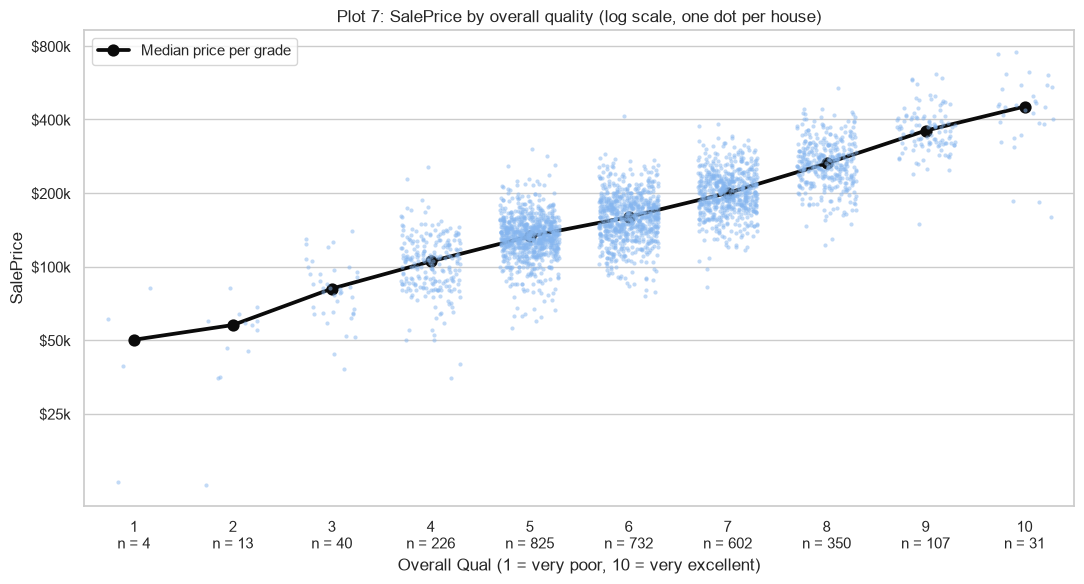

,n,median,ratio to previous median
Overall Qual,,,
1,4,50150.0,NaN
2,13,57625.0,1.15
3,40,81200.0,1.41
4,226,105000.0,1.29
5,825,133000.0,1.27
6,732,159500.0,1.20
7,602,200000.0,1.25
8,350,264530.5,1.32
9,107,360000.0,1.36


Typical step: ×1.27 per grade


In [10]:
fig, ax = plt.subplots(figsize=(11, 6))
sns.stripplot(data=housing_clean, x="Overall Qual", y=target, color="#86b6ef", alpha=0.5, size=3, jitter=0.3, ax=ax)
sns.pointplot(data=housing_clean, x="Overall Qual", y=target, estimator="median", errorbar=None, color="#0b0b0b", label="Median price per grade", ax=ax)
ax.set_yscale("log")
ax.set_yticks([25_000, 50_000, 100_000, 200_000, 400_000, 800_000])
ax.yaxis.set_major_formatter(k_dollars)
ax.yaxis.set_minor_formatter(NullFormatter())

# Number of houses per grade, written under each grade
counts = housing_clean["Overall Qual"].value_counts().sort_index()
ax.set_xticks(range(len(counts)), [f"{g}\nn = {n}" for g, n in counts.items()])

ax.set_title("Plot 7: SalePrice by overall quality (log scale, one dot per house)")
ax.set_xlabel("Overall Qual (1 = very poor, 10 = very excellent)")
ax.set_ylabel("SalePrice")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

# Median price per grade and the factor from one grade to the next
stats = housing_clean.groupby("Overall Qual")[target].agg(n="size", median="median")
stats["ratio to previous median"] = stats["median"] / stats["median"].shift()
display(stats.round(2))
print(f"Typical step: ×{stats['ratio to previous median'].median():.2f} per grade")

**Findings:** The median rises with every grade, from \$50,150 (grade 1, n = 4) to \$451,950 (grade 10, n = 31). Each step multiplies the median by 1.15–1.41, typically by 1.27 (+27 %).

**How to read it:** On a log axis, equal steps mean equal percentages. The median line is almost straight, so each grade adds about the same percentage to the price, not the same dollar amount. Grades 1–3 contain only 4–40 houses, so their medians are unreliable. The clouds of neighboring grades overlap: quality explains much of the price, but not all of it.

**Consequence:** Keep `Overall Qual` as an integer and pair it with `log(SalePrice)`. Note that the strongest predictor is an assessor's judgment, i.e. a subjective rating.

### Plot 8: Price by neighborhood

**Question:** How much does location alone shift the price, and do the 28 neighborhoods form clear price tiers?

**Motivation:** Location is the classic price factor in real estate, and `Neighborhood` is the only direct location column. With 28 levels, the right encoding (one-hot, tiers, target encoding) depends on how strongly the groups differ and how small the smallest ones are.

**Plot:** Horizontal box plots per neighborhood, sorted by median price, with the number of houses in each label and a dashed line at the overall median. The table below lists the count and median per neighborhood.

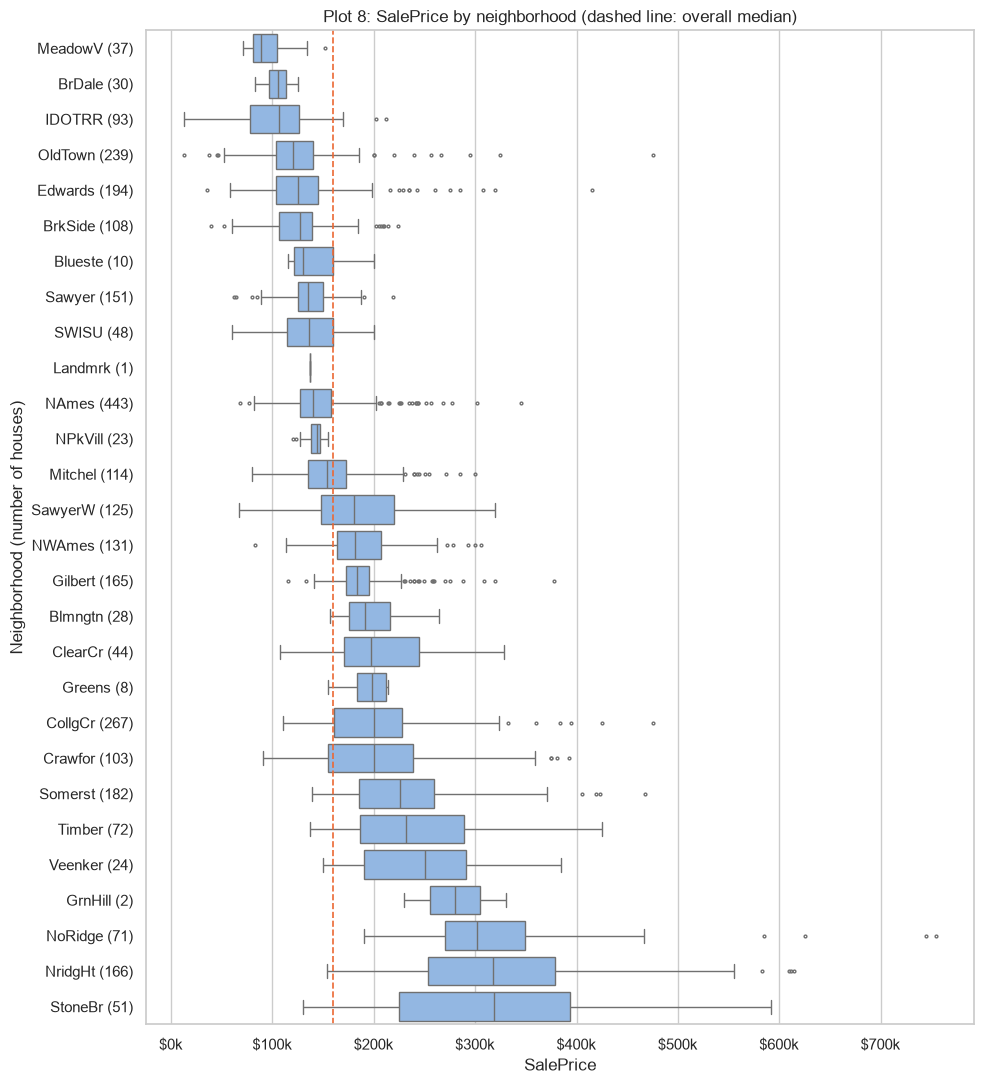

Highest / lowest median: 3.6


,count,median
Neighborhood,,
MeadowV,37,88250.0
BrDale,30,106000.0
IDOTRR,93,106500.0
OldTown,239,119900.0
Edwards,194,125000.0
BrkSide,108,126750.0
Blueste,10,130500.0
Sawyer,151,135000.0
SWISU,48,136200.0


In [11]:
by_hood = housing_clean.groupby("Neighborhood")[target].agg(["count", "median"]).sort_values("median")
order = by_hood.index

fig, ax = plt.subplots(figsize=(10, 11))
sns.boxplot(data=housing_clean, y="Neighborhood", x=target, order=order, color="#86b6ef", fliersize=2, linewidth=1, ax=ax)
ax.axvline(housing_clean[target].median(), color="#eb6834", linestyle="--", linewidth=1.2)
ax.set_yticks(range(len(order)), labels=[f"{hood} ({by_hood.loc[hood, 'count']})" for hood in order])
ax.xaxis.set_major_formatter(k_dollars)
ax.set_title("Plot 8: SalePrice by neighborhood (dashed line: overall median)")
ax.set_xlabel("SalePrice")
ax.set_ylabel("Neighborhood (number of houses)")
plt.tight_layout()
plt.show()

print(f"Highest / lowest median: {by_hood['median'].iloc[-1] / by_hood['median'].iloc[0]:.1f}")
display(by_hood)

**Findings:** The medians range from \$88,250 (MeadowV) to \$319,000 (StoneBr), a factor of 3.6. Bottom: MeadowV, BrDale, IDOTRR (\$88,250–\$106,500); top: NoRidge, NridgHt, StoneBr (\$302,000–\$319,000). Tiny groups: Landmrk (1 house), GrnHill (2), Greens (8), Blueste (10).

**How to read it:** Boxes that do not overlap mean that location alone separates the prices. The long middle section overlaps heavily, so there size and quality decide. A long box within one neighborhood means mixed housing stock. Medians based on fewer than 10 houses are anecdotes.

**Consequence:** `Neighborhood` is a must-have feature. For Task 2, group the neighborhoods into 3–5 price tiers or target-encode them on the training folds only (otherwise the target leaks), and merge the four tiny groups into neighboring ones. For Task 3, check whether the clusters rediscover these tiers.

### Plot 9: Building type vs. price (`Bldg Type` vs. `SalePrice`)

**Question:** How do the density and spread of sale prices differ between single-family houses, townhouses and two-family houses?

**Plot:** Violin plot (a combination of box plot and kernel density estimate) with the quartiles drawn inside each violin. The table below lists the count, median, IQR and share of houses below \$150,000 per building type.

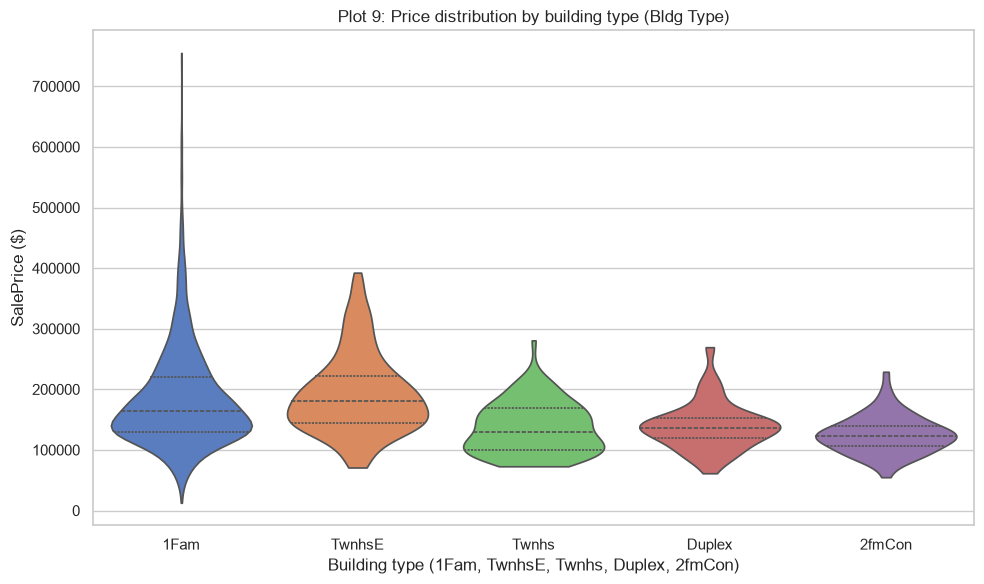

,count,median,IQR,below 150k (%)
Bldg Type,,,,
1Fam,2425,165000.0,90000.0,40.7
2fmCon,62,122250.0,33437.5,80.6
Duplex,109,136905.0,34479.0,70.6
Twnhs,101,130000.0,69500.0,66.3
TwnhsE,233,180000.0,77000.0,30.9


In [12]:
plt.figure(figsize=(10, 6))
sns.violinplot(
    data=housing_clean,
    x="Bldg Type",
    y=target,
    hue="Bldg Type",
    palette="muted",
    legend=False,
    inner="quartile",
    cut=0,
)

plt.title("Plot 9: Price distribution by building type (Bldg Type)")
plt.xlabel("Building type (1Fam, TwnhsE, Twnhs, Duplex, 2fmCon)")
plt.ylabel("SalePrice ($)")
plt.tight_layout()
plt.show()

bldg = housing_clean.groupby("Bldg Type")[target]
display(pd.DataFrame({
    "count": bldg.size(),
    "median": bldg.median(),
    "IQR": bldg.quantile(0.75) - bldg.quantile(0.25),
    "below 150k (%)": bldg.apply(lambda s: (s < 150_000).mean() * 100),
}).round(1))

**Interpretation:**
- **1Fam (single-family detached):** The large majority of the dataset (2,425 houses). It shows the widest spread and covers the whole price range up to \$755,000.
- **TwnhsE (townhouse end unit):** A clearly higher median than inner townhouses (`Twnhs`): \$180,000 vs. \$130,000, even above single-family houses (\$165,000). Its spread is not narrower, though (IQR \$77,000 vs. \$69,500).
- **Duplex and 2fmCon (two-family conversion):** Concentrated in the lower price segment (71 % and 81 % of the houses below \$150,000), with hardly any expensive outliers.

### Plot 10: The condition paradox

**Question:** Why does a better condition rating go together with a lower price overall (ρ = −0.17)?

**Motivation:** The correlation matrix behind Plot 5 shows a negative correlation between `Overall Cond` and the price, which contradicts common sense. A sign that defies common sense usually points to a hidden third variable. Age is the obvious suspect: assessors give new houses the default rating 5.

**Plot:** Box plots of the price per condition grade with a shared logarithmic y-axis: on the left all houses, on the right only houses older than 30 years. Below: the median per grade for both groups, and the distribution of condition grades per age group (row percentages).

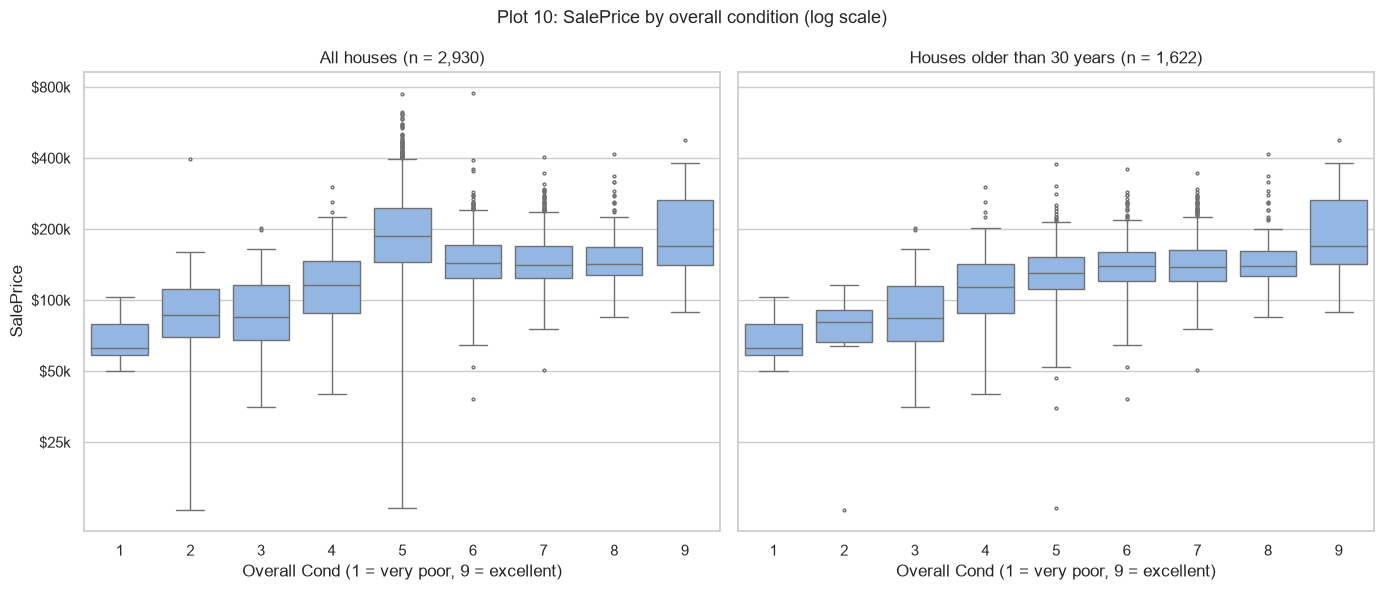

Spearman ρ (Overall Cond, SalePrice): all houses -0.17, older than 30 years 0.26


,"median, all houses","median, older than 30 years","n, older than 30 years"
Overall Cond,,,
1,62500.0,62500.0,7
2,86000.0,80750.0,8
3,84500.0,84000.0,49
4,115000.0,113000.0,97
5,187000.0,130000.0,487
6,142500.0,139000.0,448
7,139700.0,137500.0,351
8,141750.0,139250.0,136
9,168000.0,168000.0,39


Overall Cond,1,2,3,4,5,6,7,8,9
Age (years),,,,,,,,,
0–10,0.0,0.1,0.0,0.0,98.1,1.8,0.0,0.0,0.0
11–30,0.0,0.2,0.2,0.9,71.2,16.0,9.1,1.9,0.5
31–60,0.1,0.1,2.5,5.2,37.6,29.6,18.3,5.2,1.3
> 60,1.0,1.2,3.9,7.3,16.9,24.2,27.4,13.9,4.4


In [13]:
# One house was sold before its construction year (pre-sale) -> age 0
age = (housing_clean["Yr Sold"] - housing_clean["Year Built"]).clip(lower=0)
age_group = pd.cut(age, [-1, 10, 30, 60, 140], labels=["0–10", "11–30", "31–60", "> 60"]).rename("Age (years)")
older = housing_clean[age > 30]

fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=True)
for ax, data, title in [
    (axes[0], housing_clean, f"All houses (n = {len(housing_clean):,})"),
    (axes[1], older, f"Houses older than 30 years (n = {len(older):,})"),
]:
    sns.boxplot(data=data, x="Overall Cond", y=target, color="#86b6ef", fliersize=2, linewidth=1, ax=ax)
    ax.set_title(title)
    ax.set_xlabel("Overall Cond (1 = very poor, 9 = excellent)")
axes[0].set_yscale("log")
axes[0].set_yticks([25_000, 50_000, 100_000, 200_000, 400_000, 800_000])
axes[0].yaxis.set_major_formatter(k_dollars)
axes[0].yaxis.set_minor_formatter(NullFormatter())
axes[0].set_ylabel("SalePrice")
fig.suptitle("Plot 10: SalePrice by overall condition (log scale)", fontsize=13)
plt.tight_layout()
plt.show()

rho_all = housing_clean["Overall Cond"].corr(housing_clean[target], method="spearman")
rho_older = older["Overall Cond"].corr(older[target], method="spearman")
print(f"Spearman ρ (Overall Cond, SalePrice): all houses {rho_all:.2f}, older than 30 years {rho_older:.2f}")
display(pd.DataFrame({
    "median, all houses": housing_clean.groupby("Overall Cond")[target].median(),
    "median, older than 30 years": older.groupby("Overall Cond")[target].median(),
    "n, older than 30 years": older.groupby("Overall Cond").size(),
}))
display((pd.crosstab(age_group, housing_clean["Overall Cond"], normalize="index") * 100).round(1))

**Findings:** Across all houses, grade 5 has the highest median (\$187,000), while grades 6–8 sit around \$140,000. 98 % of the houses up to 10 years old are rated 5. Among the 1,622 houses older than 30 years, the median rises from \$62,500 (grade 1) over \$130,000 (grade 5) to \$168,000 (grade 9), and ρ turns positive (+0.26).

**How to read it:** The left panel mixes two groups: new, expensive houses (almost all rated 5) and older, cheaper houses that are rated 6–8 because they are well kept for their age. Holding age roughly fixed (right panel) turns the relationship positive. This is Simpson's paradox: a confounder reverses a correlation.

**Consequence:** Never drop a feature because of a weak or odd pooled correlation. `Overall Cond` is informative together with age. This plot is the clearest example of the "connections between features" that the assignment asks for.